# Reducción de dimensionalidad: PCA frente a SVD, y un vistazo a t-SNE y UMAP

**Curso:** Data Mining, semana 9 (Sistemas de recomendación, parte 1).
**Base:** diapositivas de la sesión 09 y el capítulo 11 de Mining of Massive Datasets (Leskovec, Rajaraman y Ullman).

La sesión plantea los modelos de factores latentes como tercer enfoque de recomendación: en lugar de comparar usuarios o ítems directamente, se descompone la matriz de utilidad en unos pocos factores ocultos. Este notebook construye esa idea desde la base.

Contenido:

1. PCA paso a paso con un ejemplo numérico de cinco puntos.
2. Varianza explicada, ventajas de PCA y su principal limitación.
3. SVD paso a paso con una matriz de 2 × 3.
4. Relación exacta entre PCA y SVD.
5. Tres aplicaciones de la SVD: recomendación, compresión de imágenes y búsqueda semántica.
6. Más allá de lo lineal: t-SNE y UMAP sobre dígitos manuscritos.
7. Tabla comparativa final.

Todas las técnicas se implementan desde cero en el módulo implementacion/reduccion.py, usando solo NumPy. Las versiones de NumPy y scikit-learn aparecen únicamente para verificar los resultados.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, os.path.abspath('../implementacion'))
from reduccion import pca, svd, reconstruir, pca_via_svd, tsne, umap

np.set_printoptions(precision=3, suppress=True)
FIGS = os.path.abspath('../figs')
os.makedirs(FIGS, exist_ok=True)

# Paleta: tinta del curso para diagramas y paleta categórica validada para clases
AZUL, AZUL_MED, NARANJA, VERDE, GRIS = '#1F4E79', '#2E75B6', '#C55A11', '#548235', '#808080'
CATEG = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
DIVERGENTE = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efea', '#eb6834'])

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9a9a9a', 'axes.labelcolor': '#333333',
    'xtick.color': '#555555', 'ytick.color': '#555555',
    'axes.grid': True, 'grid.color': '#e6e6e6', 'grid.linewidth': 0.8,
    'svg.fonttype': 'none', 'pdf.fonttype': 42, 'figure.dpi': 110,
})

def guardar(fig, nombre):
    # Cada figura se guarda en PDF (para el .tex) y en SVG (para la infografía)
    for ext in ('pdf', 'svg'):
        fig.savefig(f'{FIGS}/{nombre}.{ext}', bbox_inches='tight')

## 1. PCA: análisis de componentes principales

### 1.1 Idea

PCA crea variables nuevas, llamadas componentes principales, que son combinaciones lineales de las originales. La primera componente es la dirección en la que los datos varían más; la segunda es la dirección de mayor varianza entre las que son perpendiculares a la primera, y así sucesivamente. Quedarse con las primeras k componentes equivale a ver los datos desde el ángulo que conserva más información.

El algoritmo tiene cinco pasos:

1. Centrar los datos restando la media de cada variable.
2. Calcular la matriz de covarianza $C = \frac{1}{n-1} X_c^\top X_c$.
3. Obtener los autovectores de $C$ y ordenarlos por autovalor de mayor a menor.
4. Proyectar: $Z = X_c W_k$, donde las columnas de $W_k$ son los k primeros autovectores.
5. Medir la varianza explicada de cada componente: $\lambda_i / \sum_j \lambda_j$.

### 1.2 Ejemplo numérico

Se usan cinco puntos en dos dimensiones, elegidos para que las cuentas salgan exactas.

In [2]:
X = np.array([[7, 6], [1, 0], [5, 2], [3, 4], [4, 3]], dtype=float)

# Paso 1: centrar
media = X.mean(axis=0)
Xc = X - media
print('Media:', media)
print('Datos centrados:\n', Xc)

Media: [4. 3.]
Datos centrados:
 [[ 3.  3.]
 [-3. -3.]
 [ 1. -1.]
 [-1.  1.]
 [ 0.  0.]]


La media es (4, 3). Al restarla, la nube queda centrada en el origen, condición necesaria para que la covarianza mida dispersión alrededor del centro y no alrededor del cero de los ejes.

In [3]:
# Paso 2: matriz de covarianza
n = X.shape[0]
C = Xc.T @ Xc / (n - 1)
print('Xc^T Xc =\n', Xc.T @ Xc)
print('C =\n', C)

Xc^T Xc =
 [[20. 16.]
 [16. 20.]]
C =
 [[5. 4.]
 [4. 5.]]


La diagonal de $C$ contiene la varianza de cada variable (5 y 5) y el elemento fuera de la diagonal es la covarianza (4). Una covarianza positiva y grande indica que ambas variables suben juntas: la nube está estirada a lo largo de la diagonal.

In [4]:
# Paso 3: autovalores y autovectores con la implementación propia
res = pca(X, k=2)
print('Autovalores (varianza de cada componente):', res['varianzas'])
print('Autovectores (columnas):\n', res['componentes'])

# Comprobación: C w = lambda w
for lam, w in zip(res['varianzas'], res['componentes'].T):
    print(f'C w = {C @ w},  lambda w = {lam * w}')

Autovalores (varianza de cada componente): [9. 1.]
Autovectores (columnas):
 [[ 0.707  0.707]
 [ 0.707 -0.707]]
C w = [6.364 6.364],  lambda w = [6.364 6.364]
C w = [ 0.707 -0.707],  lambda w = [ 0.707 -0.707]


Los autovalores salen de resolver $\det(C - \lambda I) = 0$, es decir $(5-\lambda)^2 - 16 = 0$, de donde $\lambda_1 = 9$ y $\lambda_2 = 1$. El primer autovector es $w_1 = (1, 1)/\sqrt{2}$, la diagonal principal de la nube; el segundo es $w_2 = (1, -1)/\sqrt{2}$, perpendicular al primero.

La implementación no resuelve el polinomio: usa la iteración de potencia, que multiplica repetidamente un vector al azar por $C$ hasta que se alinea con la dirección dominante. Después resta esa dirección de $C$ (deflación) y repite para obtener la siguiente.

In [5]:
# Pasos 4 y 5: proyección y varianza explicada
print('Coordenadas en el espacio de componentes Z:\n', res['Z'])
print('Varianza explicada:', res['varianza_explicada'])

# Reducción a una dimensión y reconstrucción
r1 = pca(X, k=1)
print('Reconstrucción con k = 1:\n', r1['reconstruccion'])
print('Error cuadrático total:', ((X - r1['reconstruccion'])**2).sum())

Coordenadas en el espacio de componentes Z:
 [[ 4.243  0.   ]
 [-4.243 -0.   ]
 [-0.     1.414]
 [ 0.    -1.414]
 [ 0.     0.   ]]
Varianza explicada: [0.9 0.1]
Reconstrucción con k = 1:
 [[ 7.  6.]
 [ 1. -0.]
 [ 4.  3.]
 [ 4.  3.]
 [ 4.  3.]]
Error cuadrático total: 4.000000000000001


**Lectura.** La primera componente explica el 90 % de la varianza ($9 / (9 + 1)$). Al quedarse solo con ella, los puntos (5, 2) y (3, 4) colapsan sobre la media porque su desviación era perpendicular a la diagonal. El error cuadrático de reconstrucción vale 4, que es exactamente $(n-1)\lambda_2 = 4 \times 1$: lo que se pierde es la varianza de las componentes descartadas.

In [6]:
# Verificación con scikit-learn
from sklearn.decomposition import PCA as PCA_sk
sk = PCA_sk(n_components=2).fit(X)
print('sklearn, varianzas:', sk.explained_variance_)
print('sklearn, componentes (filas):\n', sk.components_)

sklearn, varianzas: [9. 1.]
sklearn, componentes (filas):
 [[ 0.707  0.707]
 [-0.707  0.707]]


Los resultados coinciden con scikit-learn salvo, a lo sumo, el signo de cada componente. El signo de un autovector es arbitrario: $w$ y $-w$ describen la misma recta.

### 1.3 Nube de puntos, eje principal y proyección

La figura muestra el proceso con una nube sintética de 150 puntos correlacionados.

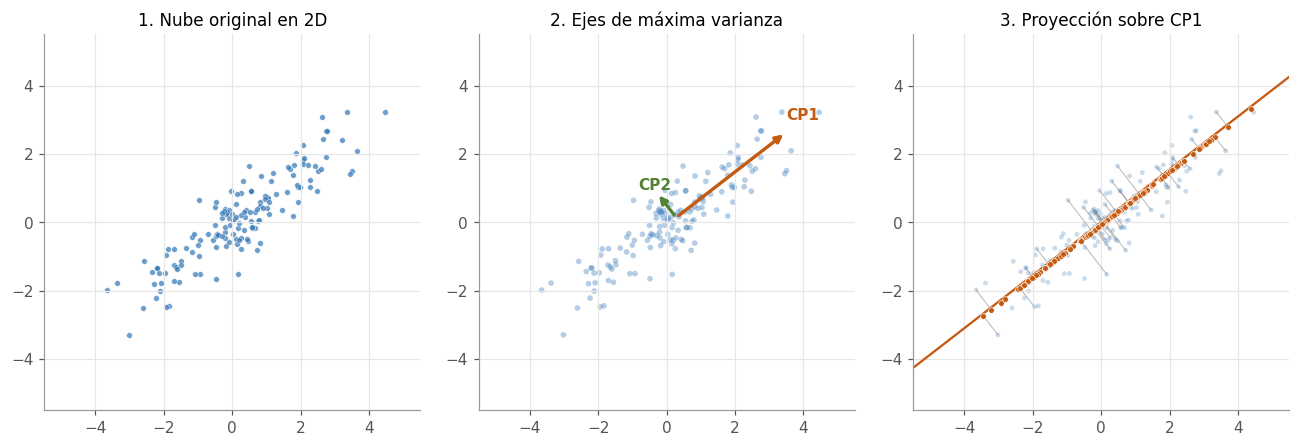

Varianza explicada por CP1: 0.952


In [7]:
rng = np.random.default_rng(7)
nube = rng.multivariate_normal([0, 0], [[3.0, 2.2], [2.2, 2.0]], size=150)
rn = pca(nube, k=2)
w1, w2 = rn['componentes'].T
z1 = rn['Z'][:, 0]
proy = np.outer(z1, w1) + rn['media']

fig, ax = plt.subplots(1, 3, figsize=(12, 3.9))
lim = 5.5
for a in ax:
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim); a.set_aspect('equal')

ax[0].scatter(*nube.T, s=14, color=AZUL_MED, alpha=0.7, edgecolor='white', linewidth=0.4)
ax[0].set_title('1. Nube original en 2D')

ax[1].scatter(*nube.T, s=14, color=AZUL_MED, alpha=0.35, edgecolor='none')
for lam, w, c, nom in [(rn['varianzas'][0], w1, NARANJA, 'CP1'), (rn['varianzas'][1], w2, VERDE, 'CP2')]:
    v = 2 * np.sqrt(lam) * w
    ax[1].annotate('', xy=rn['media'] + v, xytext=rn['media'],
                   arrowprops=dict(arrowstyle='-|>', color=c, lw=2.2))
    ax[1].text(*(rn['media'] + 1.15 * v), nom, color=c, fontweight='bold', ha='center')
ax[1].set_title('2. Ejes de máxima varianza')

t = np.linspace(-lim * 1.5, lim * 1.5, 2)
ax[2].plot(t * w1[0], t * w1[1], color=NARANJA, lw=1.5)
for p, q in zip(nube[::3], proy[::3]):
    ax[2].plot([p[0], q[0]], [p[1], q[1]], color=GRIS, lw=0.6, alpha=0.6)
ax[2].scatter(*nube.T, s=10, color=AZUL_MED, alpha=0.25, edgecolor='none')
ax[2].scatter(*proy.T, s=14, color=NARANJA, edgecolor='white', linewidth=0.4, zorder=3)
ax[2].set_title('3. Proyección sobre CP1')
fig.tight_layout()
guardar(fig, 'f01_pca_proyeccion')
plt.show()
print('Varianza explicada por CP1:', round(rn['varianza_explicada'][0], 3))

**Lectura.** La primera componente apunta a lo largo del eje mayor de la elipse y conserva cerca del 95 % de la varianza. Las líneas grises son los errores de proyección: PCA elige justamente la recta que minimiza la suma de sus cuadrados, que es la formulación original de Pearson en 1901.

### 1.4 Gráfico de varianza explicada (scree plot)

Con datos reales hay muchas variables. El conjunto de dígitos manuscritos de scikit-learn tiene 1797 imágenes de 8 × 8 píxeles, es decir, 64 variables.

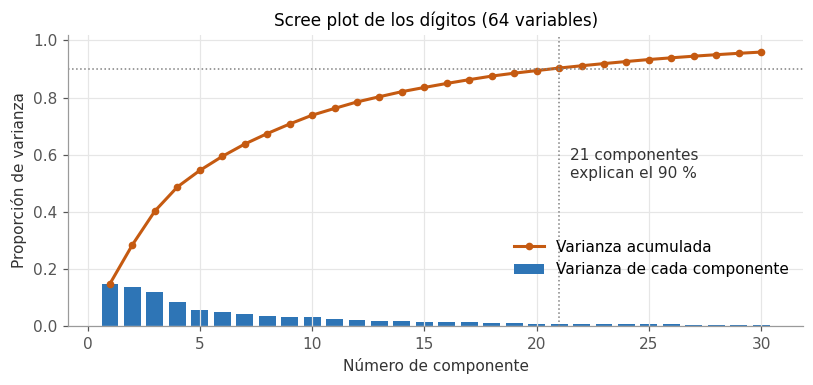

Primeras cinco proporciones: [0.149 0.136 0.118 0.084 0.058]
Componentes para el 90 %: 21


In [8]:
from sklearn.datasets import load_digits
dig = load_digits()
Xd, yd = dig.data, dig.target
rd = pca(Xd, k=64)
ve = rd['varianza_explicada']
acum = np.cumsum(ve)
k90 = int(np.argmax(acum >= 0.90)) + 1

fig, ax = plt.subplots(figsize=(7.5, 3.6))
m = 30
ax.bar(np.arange(1, m + 1), ve[:m], color=AZUL_MED, width=0.75, label='Varianza de cada componente')
ax.plot(np.arange(1, m + 1), acum[:m], color=NARANJA, marker='o', ms=4, lw=2, label='Varianza acumulada')
ax.axhline(0.90, color=GRIS, ls=':', lw=1)
ax.axvline(k90, color=GRIS, ls=':', lw=1)
ax.text(k90 + 0.5, 0.52, f'{k90} componentes\nexplican el 90 %', color='#333333')
ax.set_xlabel('Número de componente'); ax.set_ylabel('Proporción de varianza')
ax.set_ylim(0, 1.02); ax.legend(frameon=False, loc='lower right', bbox_to_anchor=(1, 0.12))
ax.set_title('Scree plot de los dígitos (64 variables)')
fig.tight_layout(); guardar(fig, 'f02_scree_digitos'); plt.show()
print('Primeras cinco proporciones:', ve[:5].round(3))
print('Componentes para el 90 %:', k90)

**Lectura.** La varianza cae rápido: las dos primeras componentes explican cerca del 29 % y con 21 componentes se alcanza el 90 %. Se puede pasar de 64 a 21 variables conservando casi toda la información. El codo de la curva sugiere dónde cortar.

### 1.5 Ventajas de PCA

**Reducción de ruido.** El ruido se reparte en todas las direcciones, mientras que la señal se concentra en las primeras componentes. Reconstruir con pocas componentes descarta buena parte del ruido.

Error medio antes de filtrar : 16.02
Error medio tras PCA (k = 12): 7.18


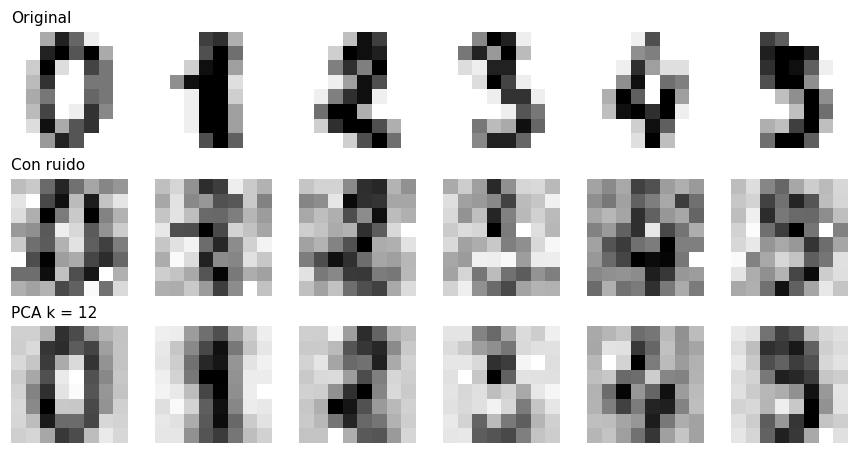

In [9]:
rng = np.random.default_rng(0)
limpias = Xd[:600]
ruidosas = limpias + rng.normal(scale=4.0, size=limpias.shape)
rr = pca(ruidosas, k=12)
filtradas = rr['reconstruccion']
print('Error medio antes de filtrar :', ((ruidosas - limpias)**2).mean().round(2))
print('Error medio tras PCA (k = 12):', ((filtradas - limpias)**2).mean().round(2))

fig, ax = plt.subplots(3, 6, figsize=(8, 4.2))
for j in range(6):
    for i, (img, tit) in enumerate([(limpias, 'Original'), (ruidosas, 'Con ruido'), (filtradas, 'PCA k = 12')]):
        ax[i, j].imshow(img[j].reshape(8, 8), cmap='gray_r'); ax[i, j].axis('off')
        if j == 0:
            ax[i, j].set_title(tit, loc='left', fontsize=10)
fig.tight_layout(); guardar(fig, 'f03_pca_ruido'); plt.show()

**Velocidad de entrenamiento.** Menos variables implica menos cálculo. Se compara un clasificador de vecinos más cercanos con las 64 variables originales y con 21 componentes.

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.3, random_state=0)
rp = pca(Xtr, k=k90)
Ztr = rp['Z']; Zte = (Xte - rp['media']) @ rp['componentes']

for nombre, A, B in [('64 variables', Xtr, Xte), (f'{k90} componentes', Ztr, Zte)]:
    t0 = time.perf_counter()
    for _ in range(20):
        acc = KNeighborsClassifier(5).fit(A, ytr).score(B, yte)
    print(f'{nombre:15s}  exactitud = {acc:.3f}   tiempo = {(time.perf_counter() - t0) / 20 * 1000:.1f} ms')

64 variables     exactitud = 0.981   tiempo = 10.9 ms
21 componentes   exactitud = 0.980   tiempo = 3.8 ms


**Visualización.** Proyectar sobre dos componentes permite dibujar datos de 64 dimensiones en un plano; se verá en la sección 4, junto con t-SNE y UMAP.

### 1.6 Limitación clave: se pierde la interpretabilidad

Cada componente mezcla todas las variables originales. La primera componente de los dígitos asigna un peso a cada uno de los 64 píxeles, con signos positivos y negativos, y ya no responde a una pregunta sencilla como cuánta tinta hay en el píxel (3, 4).

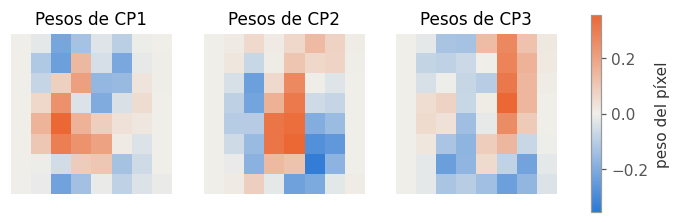

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(8, 2.9))
for i in range(3):
    w = rd['componentes'][:, i].reshape(8, 8)
    v = np.abs(w).max()
    im = ax[i].imshow(w, cmap=DIVERGENTE, vmin=-v, vmax=v)
    ax[i].set_title(f'Pesos de CP{i + 1}'); ax[i].axis('off')
fig.colorbar(im, ax=ax, shrink=0.8, label='peso del píxel')
guardar(fig, 'f04_pca_pesos'); plt.show()

**Lectura.** Los pesos de cada componente son patrones de contraste repartidos en toda la imagen. Sirven para comprimir y para separar grupos, pero explicar una predicción en términos de CP1 o CP2 es mucho más difícil que hacerlo en términos de las variables originales. Otras limitaciones son que PCA solo captura estructura lineal y que es sensible a la escala de las variables, por lo que conviene estandarizarlas cuando están en unidades distintas.

## 2. SVD: descomposición en valores singulares

### 2.1 La ecuación

Toda matriz $A$ de tamaño $m \times n$ se puede escribir como

$$A = U \Sigma V^\top$$

1. $U$ ($m \times r$): vectores singulares izquierdos. En recomendación, cada fila describe a un usuario en términos de los factores ocultos.
2. $\Sigma$ ($r \times r$): matriz diagonal con los valores singulares $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$. Cada uno mide la importancia de un factor.
3. $V^\top$ ($r \times n$): vectores singulares derechos. Cada columna describe a un ítem en términos de los mismos factores.

Leída como suma, $A = \sum_i \sigma_i u_i v_i^\top$: la matriz es una superposición de capas de rango uno, ordenadas de la más importante a la menos importante. Truncar en $k$ capas da la mejor aproximación de rango $k$ posible en norma de Frobenius (teorema de Eckart y Young).

### 2.2 Ejemplo numérico

El algoritmo implementado tiene tres pasos:

1. Los vectores $v_i$ son los autovectores de $A^\top A$.
2. Los valores singulares son $\sigma_i = \sqrt{\lambda_i}$.
3. Los vectores $u_i$ se obtienen como $u_i = A v_i / \sigma_i$.

In [12]:
A = np.array([[3, 2, 2], [2, 3, -2]], dtype=float)
print('A^T A =\n', A.T @ A)
print('A A^T =\n', A @ A.T)
U, s, Vt = svd(A, k=2)
print('Valores singulares:', s)
print('U =\n', U)
print('V^T =\n', Vt)
print('U S V^T =\n', reconstruir(U, s, Vt))

A^T A =
 [[13. 12.  2.]
 [12. 13. -2.]
 [ 2. -2.  8.]]
A A^T =
 [[17.  8.]
 [ 8. 17.]]
Valores singulares: [5. 3.]
U =
 [[ 0.707  0.707]
 [ 0.707 -0.707]]
V^T =
 [[ 0.707  0.707 -0.   ]
 [ 0.236 -0.236  0.943]]
U S V^T =
 [[ 3.  2.  2.]
 [ 2.  3. -2.]]


**Lectura.** $A A^\top = \begin{pmatrix} 17 & 8 \\ 8 & 17 \end{pmatrix}$ tiene autovalores 25 y 9, así que $\sigma_1 = 5$ y $\sigma_2 = 3$. Los autovectores son $u_1 = (1, 1)/\sqrt{2}$ y $u_2 = (1, -1)/\sqrt{2}$, y de $v_i = A^\top u_i / \sigma_i$ se obtiene $v_1 = (1, 1, 0)/\sqrt{2}$ y $v_2 = (1, -1, 4)/(3\sqrt{2})$. El producto $U \Sigma V^\top$ recupera $A$ exactamente.

In [13]:
A1 = reconstruir(U, s, Vt, k=1)
print('Aproximación de rango 1:\n', A1)
print('Error de Frobenius:', np.linalg.norm(A - A1).round(4), ' (igual a sigma_2 =', s[1], ')')
print('Verificación con NumPy:', np.linalg.svd(A, compute_uv=False))

Aproximación de rango 1:
 [[ 2.5  2.5 -0. ]
 [ 2.5  2.5 -0. ]]
Error de Frobenius: 3.0  (igual a sigma_2 = 2.9999999999999996 )
Verificación con NumPy: [5. 3.]


La mejor aproximación de rango uno es $5 u_1 v_1^\top$, una matriz con 2,5 en las dos primeras columnas y 0 en la tercera. Su error de Frobenius es exactamente $\sigma_2 = 3$: el error de truncar es la raíz de la suma de los cuadrados de los valores singulares descartados.

### 2.3 Geometría: rotar, estirar, rotar

Toda transformación lineal se descompone en una rotación ($V^\top$), un estiramiento a lo largo de los ejes ($\Sigma$) y otra rotación ($U$). La figura lo muestra con el círculo unitario y la matriz $A = \begin{pmatrix} 3 & 0 \\ 4 & 5 \end{pmatrix}$.

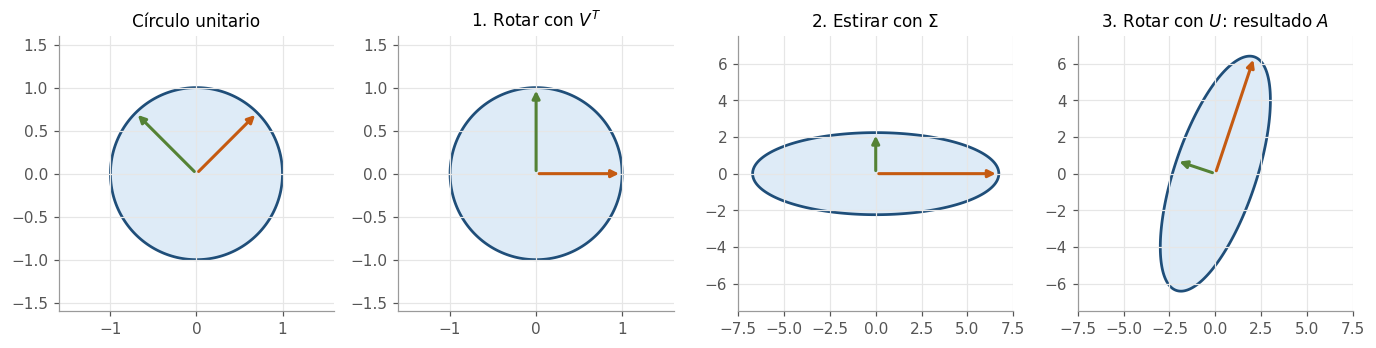

Valores singulares de M: [6.708 2.236]


In [14]:
M = np.array([[3, 0], [4, 5]], dtype=float)
Um, sm, Vtm = svd(M, k=2)
if np.linalg.det(Vtm) < 0:      # elegir signos para que V^T y U sean rotaciones puras
    Vtm[1] *= -1; Um[:, 1] *= -1
th = np.linspace(0, 2 * np.pi, 200)
circ = np.vstack([np.cos(th), np.sin(th)])
e1, e2 = np.eye(2)
etapas = [('Círculo unitario', np.eye(2)), ('1. Rotar con $V^T$', Vtm),
          ('2. Estirar con $\\Sigma$', np.diag(sm) @ Vtm), ('3. Rotar con $U$: resultado $A$', Um @ np.diag(sm) @ Vtm)]
fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.4))
for a, (tit, T) in zip(ax, etapas):
    c = T @ circ
    a.fill(*c, color='#DEEBF7', ec=AZUL, lw=1.8)
    for v, col in [(Vtm.T[:, 0], NARANJA), (Vtm.T[:, 1], VERDE)]:
        p = T @ v
        a.annotate('', xy=p, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=col, lw=2))
    lim = 7.5 if a is not ax[0] and a is not ax[1] else 1.6
    a.set_xlim(-lim, lim); a.set_ylim(-lim, lim); a.set_aspect('equal'); a.set_title(tit)
fig.tight_layout(); guardar(fig, 'f05_svd_geometria'); plt.show()
print('Valores singulares de M:', sm.round(3))

**Lectura.** Las flechas naranja y verde son $v_1$ y $v_2$. Tras la primera rotación quedan alineadas con los ejes, $\Sigma$ las estira a longitudes $\sigma_1 \approx 6{,}71$ y $\sigma_2 \approx 2{,}24$, y la última rotación las lleva a las direcciones $u_1$ y $u_2$. El círculo se convierte en una elipse cuyos semiejes son los valores singulares.

## 3. Relación entre PCA y SVD

Si $X_c = U \Sigma V^\top$ es la SVD de los datos centrados, entonces

$$C = \frac{1}{n-1} X_c^\top X_c = V \, \frac{\Sigma^2}{n-1} \, V^\top$$

Por lo tanto:

1. Las componentes principales son las columnas de $V$.
2. Las varianzas de las componentes son $\lambda_i = \sigma_i^2 / (n-1)$.
3. Las coordenadas proyectadas son $Z = X_c V = U \Sigma$.

PCA es una aplicación de la SVD a datos centrados. La SVD es más general: no exige centrar y se aplica a cualquier matriz, incluso dispersa. En la práctica, scikit-learn calcula PCA mediante SVD porque evita formar $X_c^\top X_c$, que eleva al cuadrado el número de condición.

In [15]:
r_cov = pca(X, k=2)
r_svd = pca_via_svd(X, k=2)
U5, s5, _ = svd(X - X.mean(0), k=2)
print('Valores singulares de Xc:', s5)
print('sigma^2 / (n - 1)       :', s5**2 / (len(X) - 1))
print('Autovalores de C        :', r_cov['varianzas'])
print('Mismas componentes      :', np.allclose(np.abs(r_cov['componentes']), np.abs(r_svd['componentes'])))

Valores singulares de Xc: [6. 2.]
sigma^2 / (n - 1)       : [9. 1.]
Autovalores de C        : [9. 1.]
Mismas componentes      : True


Con el ejemplo de cinco puntos, $X_c$ tiene valores singulares 6 y 2; al elevarlos al cuadrado y dividir por $n - 1 = 4$ se obtienen 9 y 1, los mismos autovalores de la covarianza.

## 4. Tres aplicaciones de la SVD

### 4.1 Compresión de imágenes

Una imagen en escala de grises es una matriz. Guardar la aproximación de rango $k$ requiere $k(m + n + 1)$ números en lugar de $m \times n$.

SVD propia de 512 x 512 con k = 50: 1.50 s
k = 10: energía conservada 0.9818, error relativo 0.135
k = 50: energía conservada 0.9960, error relativo 0.064


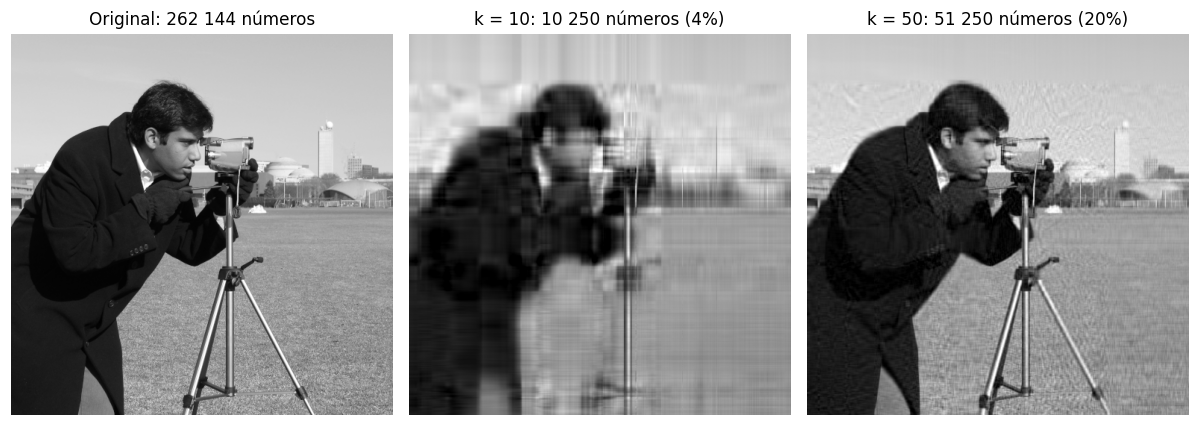

In [16]:
from skimage import data
img = data.camera().astype(float)
m_, n_ = img.shape
t0 = time.perf_counter()
Ui, si, Vti = svd(img, k=50)
print(f'SVD propia de {m_} x {n_} con k = 50: {time.perf_counter() - t0:.2f} s')
total = (img**2).sum()

fig, ax = plt.subplots(1, 3, figsize=(11, 4))
for a, k in zip(ax, [None, 10, 50]):
    if k is None:
        a.imshow(img, cmap='gray'); a.set_title(f'Original: {m_ * n_:,} números'.replace(',', ' '))
    else:
        rec = reconstruir(Ui, si, Vti, k)
        energia = (si[:k]**2).sum() / total
        a.imshow(np.clip(rec, 0, 255), cmap='gray')
        a.set_title(f'k = {k}: {k * (m_ + n_ + 1):,} números ({k * (m_ + n_ + 1) / (m_ * n_):.0%})'.replace(',', ' '))
        print(f'k = {k:2d}: energía conservada {energia:.4f}, error relativo {np.linalg.norm(img - rec) / np.sqrt(total):.3f}')
    a.axis('off')
fig.tight_layout(); guardar(fig, 'f06_svd_imagen'); plt.show()

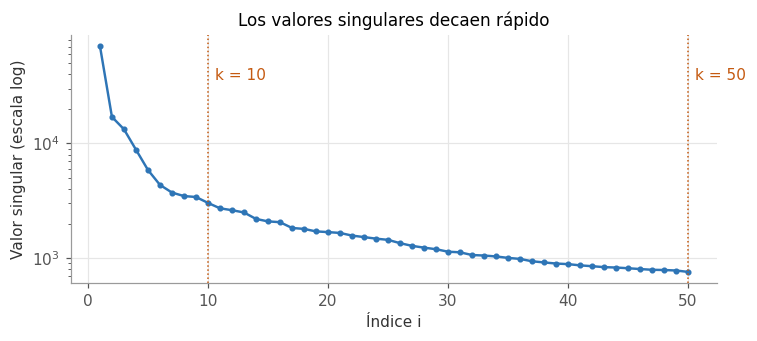

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.semilogy(np.arange(1, 51), si, color=AZUL_MED, marker='o', ms=3, lw=1.6)
for k in (10, 50):
    ax.axvline(k, color=NARANJA, ls=':', lw=1)
    ax.text(k + 0.6, si[0] * 0.5, f'k = {k}', color=NARANJA)
ax.set_xlabel('Índice i'); ax.set_ylabel('Valor singular (escala log)')
ax.set_title('Los valores singulares decaen rápido')
fig.tight_layout(); guardar(fig, 'f07_valores_singulares'); plt.show()

**Lectura.** El primer valor singular domina por un orden de magnitud. Con $k = 10$ ya se reconoce la escena usando menos del 4 % de los números; con $k = 50$ el error relativo baja a cerca del 6 % ocupando alrededor del 20 % del espacio original.

### 4.2 Recomendación: factores latentes

Se construye una matriz de utilidad sintética con 40 usuarios y 12 películas. Las seis primeras son de ciencia ficción y las seis últimas son románticas; cada usuario tiene una afinidad oculta con cada género. Se esconde el 30 % de las calificaciones y se intenta predecirlas.

El procedimiento de imputación iterativa con SVD es:

1. Rellenar los huecos con la media de cada película.
2. Calcular la SVD de rango $k$ de la matriz rellena.
3. Reemplazar solo los huecos por los valores reconstruidos.
4. Repetir los pasos 2 y 3 hasta que las predicciones se estabilicen.

In [18]:
rng = np.random.default_rng(3)
nu, ni = 40, 12
gusto = rng.uniform(0, 1, size=(nu, 2))                       # afinidad oculta: ciencia ficción, romance
perfil = np.zeros((2, ni)); perfil[0, :6] = 1; perfil[1, 6:] = 1
R = np.clip(1 + 4 * gusto @ perfil + rng.normal(scale=0.3, size=(nu, ni)), 1, 5).round()
oculto = rng.random(R.shape) < 0.30
obs = np.where(oculto, np.nan, R)

media_item = np.nanmean(obs, axis=0)
Rk = np.where(oculto, media_item, obs)
for it in range(30):
    Ur, sr, Vtr = svd(Rk, k=2)
    Rk = np.where(oculto, reconstruir(Ur, sr, Vtr), obs)

rmse = lambda p: np.sqrt(((p[oculto] - R[oculto])**2).mean())
print('RMSE prediciendo la media de la película:', rmse(np.broadcast_to(media_item, R.shape)).round(3))
print('RMSE con SVD de rango 2                  :', rmse(np.clip(Rk, 1, 5)).round(3))
print('Valores singulares:', sr.round(2))

RMSE prediciendo la media de la película: 1.274
RMSE con SVD de rango 2                  : 0.433
Valores singulares: [69.05 19.34]


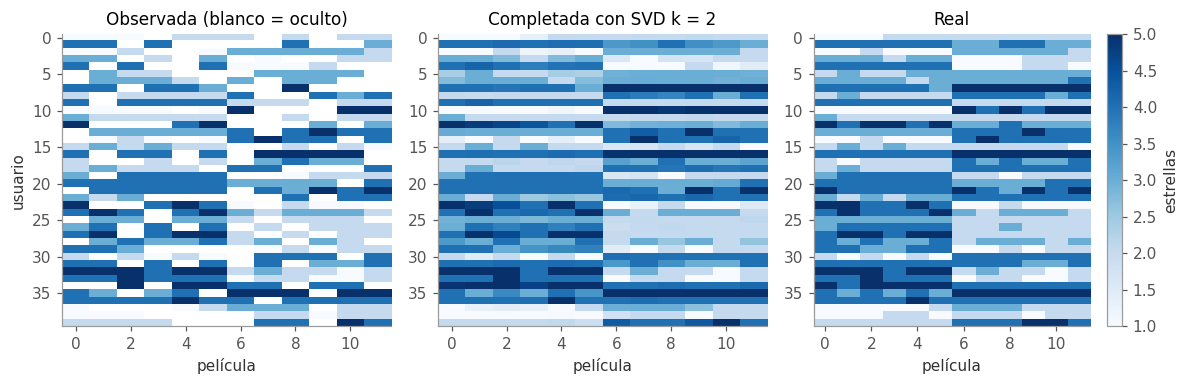

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6), gridspec_kw={'width_ratios': [1, 1, 1.05]})
for a, M_, tit in [(ax[0], obs, 'Observada (blanco = oculto)'), (ax[1], np.clip(Rk, 1, 5), 'Completada con SVD k = 2'), (ax[2], R, 'Real')]:
    im = a.imshow(M_, cmap='Blues', vmin=1, vmax=5, aspect='auto')
    a.set_title(tit); a.set_xlabel('película'); a.grid(False)
ax[0].set_ylabel('usuario')
fig.colorbar(im, ax=ax[2], label='estrellas')
fig.tight_layout(); guardar(fig, 'f08_recomendacion'); plt.show()

**Lectura.** Dos factores latentes bastan para reconstruir la estructura de la matriz. El primer valor singular resume el nivel general de calificación y el segundo separa a los aficionados de cada género. El error de la SVD es claramente menor que el de predecir la media de cada película, porque el modelo aprovecha que a un usuario que califica alto una película de ciencia ficción le gustan también las otras cinco. Esto es lo que en la sesión se llama un modelo de factores latentes; el trabajo de Koren, Bell y Volinsky (2009) lo extiende con sesgos por usuario e ítem y con regularización.

### 4.3 Búsqueda semántica (LSA)

En el análisis semántico latente se aplica SVD a la matriz término documento. Los documentos que comparten contexto quedan cerca en el espacio latente, aunque no compartan palabras exactas.

In [20]:
docs = ['auto rojo corre carretera',
        'coche nuevo motor potente',
        'auto coche vehículo motor',
        'conductor maneja auto carretera',
        'gato duerme sofá',
        'perro gato juegan casa',
        'mascota perro gato cariño',
        'perro viaja auto carretera']
vocab = sorted({w for d in docs for w in d.split()})
T = np.array([[d.split().count(w) for d in docs] for w in vocab], dtype=float)   # términos x documentos
Ut, st, Vtt = svd(T, k=2)
docs_lat = (Vtt.T * st)                   # documentos en el espacio latente

def coseno(a, b):
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12)

consulta = np.array([1.0 if w == 'coche' else 0.0 for w in vocab])
q_lat = consulta @ Ut                     # plegar la consulta: U_k^T q, comparable con U_k^T d = Sigma v
print(f'{"documento":36s} {"coseno original":>16s} {"coseno LSA":>11s}')
for i, d in enumerate(docs):
    print(f'{d:36s} {coseno(consulta, T[:, i]):16.2f} {coseno(q_lat, docs_lat[i]):11.2f}')

documento                             coseno original  coseno LSA
auto rojo corre carretera                        0.00        0.88
coche nuevo motor potente                        0.50        1.00
auto coche vehículo motor                        0.50        0.97
conductor maneja auto carretera                  0.00        0.88
gato duerme sofá                                 0.00       -0.54
perro gato juegan casa                           0.00       -0.42
mascota perro gato cariño                        0.00       -0.42
perro viaja auto carretera                       0.00        0.60


**Lectura.** La consulta coche solo coincide literalmente con dos documentos. En el espacio latente, en cambio, auto rojo corre carretera y conductor maneja auto carretera obtienen un coseno cercano a 0,9 sin contener la palabra, porque auto y coche aparecen juntas en el tercer documento y la SVD las agrupa en el mismo factor. El octavo documento, que mezcla perro y auto, queda en un valor intermedio, y los documentos sobre mascotas obtienen cosenos negativos. Esta es la base de la recuperación semántica que hoy hacen los embeddings densos.

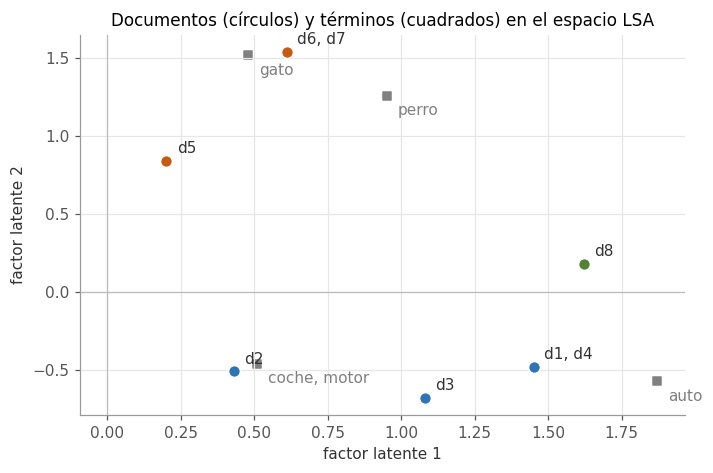

In [21]:
pal_lat = Ut * st
fig, ax = plt.subplots(figsize=(6.6, 4.4))
# Los puntos que coinciden en el espacio latente comparten una sola etiqueta
grupos = {}
for i in range(len(docs)):
    grupos.setdefault(('d', *np.round(docs_lat[i], 2)), []).append(f'd{i + 1}')
for w in ['auto', 'coche', 'motor', 'gato', 'perro']:
    grupos.setdefault(('t', *np.round(pal_lat[vocab.index(w)], 2)), []).append(w)
for (tipo, x, y), nombres in grupos.items():
    if tipo == 'd':
        i = int(nombres[0][1:]) - 1
        c = AZUL_MED if i < 4 else (NARANJA if i < 7 else VERDE)
        ax.scatter(x, y, s=60, color=c, edgecolor='white', zorder=3)
        ax.annotate(', '.join(nombres), (x, y), xytext=(7, 5), textcoords='offset points', color='#333333')
    else:
        ax.scatter(x, y, marker='s', s=30, color=GRIS)
        ax.annotate(', '.join(nombres), (x, y), xytext=(7, -13), textcoords='offset points', color=GRIS)
ax.axhline(0, color='#bbbbbb', lw=0.8); ax.axvline(0, color='#bbbbbb', lw=0.8)
ax.set_xlabel('factor latente 1'); ax.set_ylabel('factor latente 2')
ax.set_title('Documentos (círculos) y términos (cuadrados) en el espacio LSA')
fig.tight_layout(); guardar(fig, 'f09_lsa'); plt.show()

## 5. Más allá de lo lineal: t-SNE y UMAP

PCA y SVD buscan subespacios lineales. Cuando los datos viven sobre una superficie curva, como los dígitos manuscritos, la proyección lineal mezcla grupos que en realidad están separados. Las técnicas de aprendizaje de variedades preservan vecindades en lugar de varianzas.

**t-SNE** (van der Maaten y Hinton, 2008):

1. Convierte las distancias originales en probabilidades $p_{ij}$ de que $j$ sea vecino de $i$, con una gaussiana cuyo ancho se ajusta a la perplejidad (el número efectivo de vecinos).
2. En el mapa de dos dimensiones define probabilidades $q_{ij}$ con una t de Student, de colas pesadas, que deja espacio para separar grupos.
3. Mueve los puntos del mapa por descenso de gradiente para minimizar la divergencia $KL(P \parallel Q) = \sum p_{ij} \log (p_{ij}/q_{ij})$.

**UMAP** (McInnes, Healy y Melville, 2018):

1. Construye un grafo de los k vecinos más cercanos.
2. Asigna pesos difusos $w_{ij} = \exp(-(d_{ij} - \rho_i)/\sigma_i)$, donde $\rho_i$ es la distancia al vecino más cercano.
3. Simetriza con la unión difusa $w_{ij} + w_{ji} - w_{ij} w_{ji}$.
4. Optimiza un diseño en dos dimensiones con entropía cruzada: las aristas atraen y muestras negativas al azar repelen.

UMAP es hoy la opción más usada en la práctica porque escala mejor, conserva algo más de estructura global y puede transformar puntos nuevos. Para no saturar los colores se usan solo los dígitos del 0 al 5.

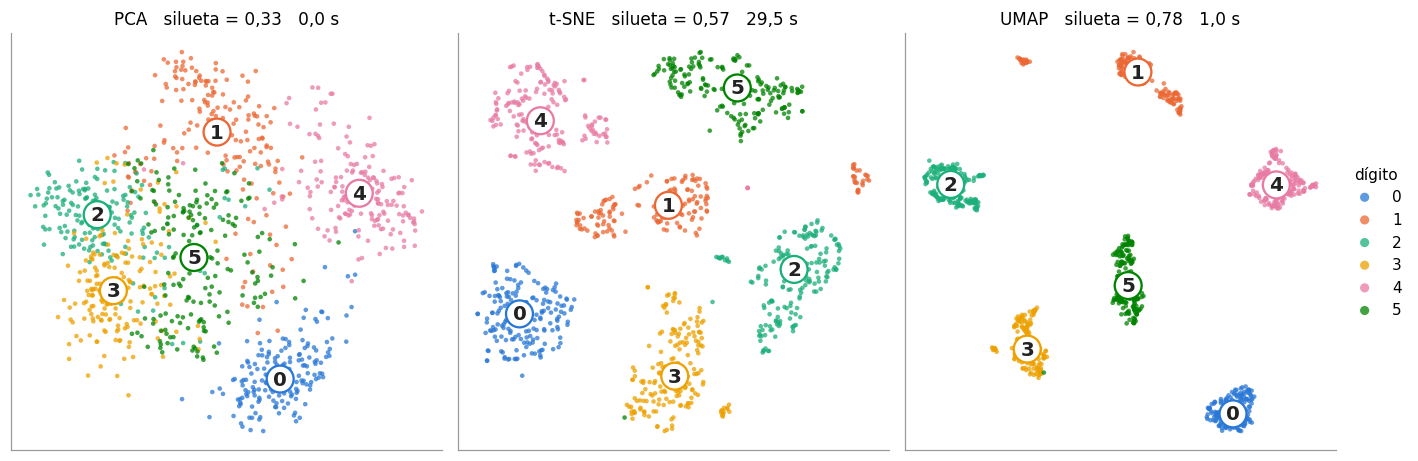

Divergencia KL final de t-SNE: 0.678


In [22]:
sel = yd <= 5
Xs, ys = Xd[sel], yd[sel]
resultados = {}
t0 = time.perf_counter(); resultados['PCA'] = pca(Xs, 2)['Z']; tp = time.perf_counter() - t0
t0 = time.perf_counter(); resultados['t-SNE'], kl = tsne(Xs, perplejidad=30, iters=750); tt = time.perf_counter() - t0
t0 = time.perf_counter(); resultados['UMAP'] = umap(Xs, vecinos=15, min_dist=0.1); tu = time.perf_counter() - t0
tiempos = {'PCA': tp, 't-SNE': tt, 'UMAP': tu}

from sklearn.metrics import silhouette_score
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a, (nom, Y) in zip(ax, resultados.items()):
    for c in range(6):
        P = Y[ys == c]
        a.scatter(*P.T, s=9, color=CATEG[c], alpha=0.75, edgecolor='none', label=str(c))
        a.text(*np.median(P, 0), str(c), fontsize=13, fontweight='bold', color='#222222',
               ha='center', va='center', bbox=dict(boxstyle='circle,pad=0.2', fc='white', ec=CATEG[c], lw=1.5))
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a.set_title(f'{nom}   silueta = {silhouette_score(Y, ys):.2f}   {tiempos[nom]:.1f} s'.replace('.', ','))
ax[2].legend(title='dígito', frameon=False, loc='center left', bbox_to_anchor=(1, 0.5), markerscale=2)
fig.tight_layout(); guardar(fig, 'f10_pca_tsne_umap'); plt.show()
print(f'Divergencia KL final de t-SNE: {kl:.3f}')

**Lectura.** PCA separa el 0 y el 4, pero el 2, el 3 y el 5 se superponen porque dos componentes lineales retienen apenas el 36 % de la varianza. t-SNE y UMAP separan los seis grupos con claridad, y el coeficiente de silueta lo confirma. Hay que leer estos mapas con cuidado: los tamaños de los grupos y las distancias entre grupos no tienen un significado métrico fiable, sobre todo en t-SNE. Por eso se usan para explorar y visualizar, no como variables de entrada de otro modelo.

## 6. Tabla comparativa

| Criterio | PCA | SVD | t-SNE | UMAP |
|---|---|---|---|---|
| Tipo | Lineal | Lineal (factorización) | No lineal | No lineal |
| Qué preserva | Varianza global | Mejor aproximación de rango k | Vecindades locales | Vecindades locales y algo de estructura global |
| Requiere centrar | Sí | No | No aplica | No aplica |
| Determinista | Sí | Sí | No | No |
| Costo típico | $O(nd^2)$ o SVD truncada | $O(mnk)$ truncada, aleatorizada | $O(n^2)$ exacto, $O(n \log n)$ con Barnes y Hut | Cerca de $O(n^{1,14})$ con vecinos aproximados |
| Transforma puntos nuevos | Sí | Sí (plegado) | No | Sí |
| Interpretabilidad | Media: pesos por variable | Media: factores latentes | Baja | Baja |
| Uso principal | Preprocesado, ruido, visualización | Recomendación, compresión, LSA | Visualización | Visualización y preprocesado para clustering |

**Recomendación práctica.**

1. Para quitar ruido, acelerar un modelo o comprimir: PCA o SVD truncada.
2. Para matrices dispersas como la de utilidad o la término documento: SVD truncada, sin centrar.
3. Para mirar la estructura de los datos en dos dimensiones: UMAP, o t-SNE si el conjunto es pequeño; conviene aplicar antes PCA a unas 50 componentes para acelerar y filtrar ruido.

## 7. Referencias

Los artículos están en la carpeta papers. Los más útiles para esta sesión son el tutorial de Shlens (2014) para PCA, el capítulo de Wall, Rechtsteiner y Rocha (2003) para la relación entre SVD y PCA, el capítulo 11 de Mining of Massive Datasets, el artículo de Koren, Bell y Volinsky (2009) sobre factorización en recomendación, y los artículos originales de t-SNE (2008) y UMAP (2018).